## **PHASE 2: LLM-BASED LABELING & GOLD-SET ANNOTATION**

The goal of this phase is to generate aspect-based sentiment labels for a training set of reviews using a local Large Language Model and to create manually labeled test set. 

**Model Selection:**
While bigger models (such as GPT-4) or larger open-source architectures could theoretically offer higher accuracy, Llama 3.1 (8B) run via Ollama balances good local machine computation capacity and processing time. Running via Ollama eliminated API costs, avoided cloud rate limits and executed reliably on local machine at approximately 12 seconds per review.   

**Aspect Scope:**
The pipeline evaluated seven skincare aspects: texture, scent, breakouts, irritation, efficacy, packaging, and value.

**Gold-Set Annotation:**
Additionally, a dedicated gold set of reviews is manually annotated by hand to serve as an independent test set (ground-truth) for final model evaluation in Phase 3.

### Step 1: Load dataset

In [ ]:

import pandas as pd
from tqdm import tqdm
import os
import ollama
import json
import re
import numpy as np
from openpyxl.styles import Alignment
from sklearn.metrics import precision_recall_fscore_support
from collections import Counter



In [3]:
# Load cleaned reviews CSV into a DataFrame
df = pd.read_csv("skincare_reviews_clean.csv")

### Step 2: Inspect review length and cap extreme long ones

In [ ]:
# Inspect review length 
print(df["review_text"].str.split().str.len().quantile([0.90, 0.95, 0.99, 1.0]))

0.90    112.0
0.95    142.0
0.99    221.0
1.00    982.0
Name: review_text, dtype: float64


In [ ]:
# Cap only the long-tail outliers before sending to the LLM, to reduce runtime without
# truncating the majority of reviews. 
# 300 words covers well above the 99th percentile (~221 words); 

def truncate_review(text, max_words=300):
    words = text.split()
    if len(words) <= max_words:
        return text
    return " ".join(words[:max_words]) + "..."

df["review_text_for_llm"] = df["review_text"].apply(truncate_review)

### Step 3: Aspect taxonomy, prompt template, and JSON parsing helpers

Aspect taxonomy, prompt, and schema-constrained extraction
extract_aspects(text) returns {aspect: "positive" | "negative" | None | "PARSE_ERROR"}.

A label is kept only if its evidence quote is really in the review and is an opinion on that
aspect (see BAD_QUOTE). Every removed label is logged: call show_dropped()

In [ ]:
# Define the aspects
ASPECTS = [
    "texture",
    "scent",
    "breakouts",
    "irritation",
    "efficacy",
    "packaging",
    "value",
]

# Define the model and context size for the LLM
MODEL = "llama3.1:8b"          
NUM_CTX = 6144                 # context window size (maximum number of tokens the model can read and generate at once
                                # Note: 8k context window is not available in the free version of Ollama, so we use 6144 tokens instead.
                                # That should cover prompts of up to ~4,500 words, which is more than enough for skincare reviews (99th percentile is ~221 words). 

# ---------------------------------------------------------------------------
# 1. JSON schema: forces valid output
# ---------------------------------------------------------------------------

# Define the schema for each aspect, ensuring that the output contains both evidence and sentiment.
# "evidence" comes BEFORE "sentiment" so the model must find the quote first.

_ASPECT_SCHEMA = {
    "type": "object",
    "properties": {
        "evidence": {"type": "string"},
        "sentiment": {"enum": ["positive", "negative", "none"]},
    },
    "required": ["evidence", "sentiment"],
}
# Define the overall response schema for the LLM output, ensuring it adheres to the expected structure for all aspects.
RESPONSE_SCHEMA = {
    "type": "object",
    "properties": {a: _ASPECT_SCHEMA for a in ASPECTS},
    "required": ASPECTS,
}

# ---------------------------------------------------------------------------
# 2. Prompt
# ---------------------------------------------------------------------------

# Define the prompt head, which provides instructions to the LLM on how to label aspect-level sentiment in reviews. 
# It includes detailed guidelines for each aspect, general rules for labeling, and examples of labeled reviews.

PROMPT_HEAD = """You label aspect-level sentiment in skincare and cosmetics reviews.

For EACH of the 7 aspects below, output:
  "evidence": ONE short contiguous quote (max 12 words) copied exactly from the review ("" if none)
  "sentiment": "positive" | "negative" | "none"

Use "none" unless the reviewer EXPRESSES A CLEAR OPINION about that aspect.
If you are unsure, or the opinion is mixed, neutral or indifferent, use "none".
Never invent evidence: it must be copied from the review. Never use the same quote for two aspects.

ASPECTS AND BOUNDARIES
- texture: how the PRODUCT itself feels or applies (creamy, greasy, sticky, light, absorbs fast, spreads easily, sprays evenly).
  Ask: what is being described? The PRODUCT -> texture. The user's SKIN, LIPS or FACE after use
  ("my lips are soft", "my skin felt so smooth") -> efficacy, never texture.
  A patch or pad absorbing gunk or fluid is what it DOES (efficacy), not texture.
  How much product you need ("a little goes a long way") is neither texture nor efficacy.
- scent: opinion about smell or fragrance ("smells amazing", "too strong", "perfume-y").
  A neutral or hesitant remark ("smells interesting", "not sure about the smell") = none.
- breakouts: acne, pimples, clogged pores caused, worsened, prevented or cleared.
  "It broke me out" = negative.
  "Didn't break me out", "no acne", "no breakouts", "cleared my acne" = positive.
  Merely having acne-prone skin = none.
- irritation: redness, burning, stinging, itching, rash, allergic reaction, sensitivity reaction (NOT acne).
  "It burned" = negative. "Didn't irritate my sensitive skin" = positive.
  Dryness or tightness caused by the product is efficacy negative, NOT irritation.
- efficacy: a stated RESULT of using the product (hydrated, faded spots, smoother skin, did nothing, made it worse).
  General praise with no result ("love it", "holy grail", "will repurchase") = none.
- packaging: the container itself: pump, tube, jar, lid, leaking, dispensing, travel-friendliness. Only if evaluated.
  How much product is inside, or the size of a sample, is NOT packaging.
- value: price or worth is evaluated. "Worth every penny" = positive.
  "Too expensive", "not worth it", "my only complaint is the price" = negative.
  Loving the product, repurchasing, or a price merely stated ("this costs $40", "I paid $25") = none.
  A price needs an opinion word (expensive, cheap, worth, overpriced, affordable) to count.

GENERAL RULES
- A problem the product FIXED is positive for efficacy ("my lips were chapped, now they are soft").
- A problem the product CAUSED or WORSENED is negative for the matching aspect.
- Judge every aspect independently. Never copy the overall tone of the review into an aspect.
- The absence of a complaint is NOT a positive. Only an explicit statement is.
- If an aspect has both praise and complaint, use the reviewer's final judgement about that aspect.

EXAMPLES
"""

# (review, {aspect: (evidence, sentiment)}); every aspect not listed = ("", "none")
EXAMPLES = [
    (
        "Love it!! Will repurchase.",
        {},
    ),
    (
        "Smells amazing but the pump broke in a week and it's too expensive for what it is.",
        {
            "scent": ("Smells amazing", "positive"),
            "packaging": ("the pump broke in a week", "negative"),
            "value": ("too expensive for what it is", "negative"),
        },
    ),
    (
        "Dried out my cheeks but no burning at all.",
        {
            "efficacy": ("Dried out my cheeks", "negative"),
            "irritation": ("no burning at all", "positive"),
        },
    ),
    (
        "Broke me out within three days.",
        {"breakouts": ("Broke me out", "negative")},
    ),
    (
        "Gel texture sinks in fast, honestly cleared my redness.",
        {
            "texture": ("sinks in fast", "positive"),
            "efficacy": ("cleared my redness", "positive"),
        },
    ),
    (
        "Did nothing for my dark spots and it's not worth $40, but at least it didn't break me out.",
        {
            "efficacy": ("Did nothing for my dark spots", "negative"),
            "value": ("not worth $40", "negative"),
            "breakouts": ("didn't break me out", "positive"),
        },
    ),
    (
        "My lips were so chapped, now they're soft all day.",
        {"efficacy": ("now they're soft all day", "positive")},
    ),
    (
        "Love the fragrance and it works great overnight. Only reason for 4 stars is the price.",
        {
            "scent": ("Love the fragrance", "positive"),
            "efficacy": ("works great overnight", "positive"),
            "value": ("Only reason for 4 stars is the price", "negative"),
        },
    ),
    (
        "I paid $40 for this at Sephora. Smells like roses, a little goes a long way.",
        {"scent": ("Smells like roses", "positive")},
    ),
    (
        "This cream feels rich and creamy. My skin felt so soft and smooth afterwards, and no acne either.",
        {
            "texture": ("feels rich and creamy", "positive"),
            "efficacy": ("My skin felt so soft and smooth afterwards", "positive"),
            "breakouts": ("no acne either", "positive"),
        },
    ),
    (
        "The patches absorb all the gunk overnight and my pimples are flat by morning.",
        {"efficacy": ("my pimples are flat by morning", "positive")},
    ),
    (
        "The sample size was tiny. It smells interesting, not sure how I feel about it yet.",
        {},
    ),
    (
        "There is so much product in this bottle and it's totally worth it.",
        {"value": ("it's totally worth it", "positive")},
    ),
]

# render an example review and its corresponding labels into a formatted string for the prompt
def _render_example(review, labels):
    out = {}
    for a in ASPECTS:
        ev, s = labels.get(a, ("", "none"))
        out[a] = {"evidence": ev, "sentiment": s}
    return f'Review: "{review}"\nOutput: {json.dumps(out, ensure_ascii=False)}\n'

# Define the prompt tail (it instructs the LLM to label a new review and return the output in JSON format with exactly the 7 aspect keys)
PROMPT_TAIL = """
Now label the following review. Return ONLY JSON with exactly the 7 aspect keys.

Review: "<<REVIEW>>"
Output:"""

# Combine the prompt head, rendered examples, and prompt tail into a single prompt template for the LLM
PROMPT_TEMPLATE = (
    PROMPT_HEAD
    + "\n".join(_render_example(r, l) for r, l in EXAMPLES)
    + PROMPT_TAIL
)

# ---------------------------------------------------------------------------
# 3. Guards: keep a label only if its quote is in the review and is a real opinion on the aspect
# ---------------------------------------------------------------------------


BAD_QUOTE = {
    "texture":   r"go(es)? a long way"                                    # amount of product, not feel
                 r"|^(?:(?:my|skin|lips?|face|hands?|so|very|really|incredibly|super|extremely|felt|feels?|feeling" # effiecacy, not texture
                 r"|and|too|is|are|was|soft(?:er)?|smooth(?:er)?|silky|supple|plump|hydrated|moisturi[sz]ed)\W*)+$",  # user's skin result
    "efficacy":  r"go(es)? a long way", # amount of product, not result
    "value":     r"^(this |it |i )?(costs? |is |was |paid )?[$\u20ac\u00a3]\s?\d[\d.,]*\W*$",   # bare price
    "packaging": r"^(?!.*\b(pump|lid|caps?|leak|dispens|spray|jar|tube|squeez|open|clos|crack|spill|broke|travel))" # not a container
                 r".*\b(so much|too much|a lot of|amount of|samples? sizes?|how many|tiny)\b",  # amount, not container
}

DROPPED = []   

def reset_stats():
    DROPPED.clear()

# Function to display the reasons for dropped labels and the last few dropped labels for review.
def show_dropped(n=30):
    print(f"{len(DROPPED)} labels dropped by guards:", dict(Counter(d["reason"] for d in DROPPED)))
    for d in DROPPED[-n:]:
        print(f"  [{d['reason']}] {d['aspect']}={d['label']} <- {d['evidence']!r}")
        print(f"      review: {d['review']!r}")

# Log a dropped label with its aspect, label, evidence, reason for dropping, and a truncated version of the review for context.
def _log(aspect, label, evidence, reason, review):
    DROPPED.append({"aspect": aspect, "label": label, "evidence": evidence, "reason": reason, "review": review[:100]})

# Function to normalize a string by converting it to lowercase, replacing certain Unicode characters with their ASCII equivalents, and removing extra whitespace and trailing punctuation.
def _norm(s):
    s = (s or "").lower()
    for a, b in {"\u2019": "'", "\u2018": "'", "\u201c": '"', "\u201d": '"', "-": " "}.items():
        s = s.replace(a, b)
    return re.sub(r"\s+", " ", s).strip(" .\u2026")

# Check if a quote should be rejected(BAD_QUOTE) or None if it is fine. `text` is the normalized review.
def _check(aspect, evidence, text):
    """Return why a quote should be rejected, or None if it is fine. `text` is the normalised review."""
    fragments = [_norm(f) for f in re.split(r"\.\.\.|\u2026", evidence) if _norm(f)]
    if not fragments or not all(f in text for f in fragments):
        return "quote not in review"
    if aspect in BAD_QUOTE and re.search(BAD_QUOTE[aspect], _norm(evidence)):
        return "quote is not an opinion on this aspect"
    return None

# Function to normalize null-like strings to None
def normalize_null(value):
    """Convert null-like strings to None (used by later notebook cells)."""
    if value is None or (isinstance(value, str) and value.strip().lower() in {"", "none", "null", "n/a", "null_value"}):
        return None
    return value

# ---------------------------------------------------------------------------
# 4. Run the LLM and apply guards
# ---------------------------------------------------------------------------
# Function to extract aspect-level sentiment from a review using the LLM. It returns a dictionary mapping each aspect to its sentiment label ("positive", "negative", or None) and optionally includes evidence quotes if requested.
# Temprature is set to 0 for deterministic output, and the number of context tokens is set to NUM_CTX.

def extract_aspects(review_text, model=MODEL, return_evidence=False):
    """Run the LLM and return {aspect: "positive" | "negative" | None} (plus evidence quotes if asked)."""
    response = ollama.chat(
        model=model,
        messages=[{"role": "user", "content": PROMPT_TEMPLATE.replace("<<REVIEW>>", review_text)}],
        format=RESPONSE_SCHEMA,
        options={"temperature": 0, "num_ctx": NUM_CTX},
    )
    try:
        parsed = json.loads(response["message"]["content"])
    except json.JSONDecodeError:
        _log("all", "", "", "parse error", review_text)
        labels = {a: "PARSE_ERROR" for a in ASPECTS}
        return (labels, dict.fromkeys(ASPECTS, "")) if return_evidence else labels

    text = _norm(review_text)
    labels, evidence = {}, {}
    for a in ASPECTS:
        item = parsed.get(a) or {}
        label, quote = item.get("sentiment"), item.get("evidence") or ""
        if label not in ("positive", "negative"):
            label, quote = None, ""
        elif (reason := _check(a, quote, text)):
            _log(a, label, quote, reason, review_text)
            label, quote = None, ""
        labels[a], evidence[a] = label, quote

    # the same quote must not be counted as both texture and efficacy (efficacy wins)
    t, e = _norm(evidence["texture"]), _norm(evidence["efficacy"])
    if labels["texture"] and labels["efficacy"] and (t in e or e in t):
        _log("texture", labels["texture"], evidence["texture"], "same quote as efficacy", review_text)
        labels["texture"], evidence["texture"] = None, ""

    return (labels, evidence) if return_evidence else labels

# Function to preview the extracted aspects and evidence for a list of review texts.
def preview(texts):
    """Print labels + evidence for each review, then what the guards removed."""
    reset_stats()
    for t in texts:
        labels, ev = extract_aspects(t, return_evidence=True)
        print(t[:90] + ("..." if len(t) > 90 else ""))
        for a in ASPECTS:
            if labels[a]:
                print(f"   {a:<11} {labels[a]:<9} <- {ev[a]!r}")
        print()
    show_dropped()

### Step 4: Smoke test
Check that the extractor identifies aspect-specific sentiment, returns evidence from the review, and leaves aspects unmentioned when there is no clear evidence.

In [181]:
# Smoke test on problematic reviews
_smoke = [
    "I love the smell of this and it didn't break me out, but the texture feels greasy. The pump is also difficult to use.",
    "It caused redness but no acne. It did nothing for my dark spots. Smells great but feels greasy. Packaging is nice though. This costs $40",
    "A little goes a long way. Love the fragrance and works great as a night lip mask. Only reason I gave it 4 stars is because of the price.",
    "i have used this for about almost a year, and my lips are so soft once i use this!",
    "Love it, will buy again!",
    "I loved this product texture wise. It wasn't sticky or too goopy. I had no irritations from this product.",
    "I've honestly never used an essence. After two weeks my skin felt so incredibly soft and smooth. There is SO much product in this bottle and it's totally worth it.",
    "These are the best pimple patches I have ever used. They absorb all the gunk from my pimples very well and quite expensive for how many you get.",
    "Really want to like this but not thrilled with the sample sizes I tested. I saw no improvement at all.",
]
preview(_smoke)



I love the smell of this and it didn't break me out, but the texture feels greasy. The pum...
   texture     negative  <- 'feels greasy'
   scent       positive  <- 'I love the smell of this'
   breakouts   positive  <- "didn't break me out"
   packaging   negative  <- 'the pump is also difficult to use'

It caused redness but no acne. It did nothing for my dark spots. Smells great but feels gr...
   texture     negative  <- 'feels greasy'
   scent       positive  <- 'Smells great'
   breakouts   positive  <- 'no acne'
   irritation  negative  <- 'caused redness'
   efficacy    negative  <- 'did nothing for my dark spots'
   packaging   positive  <- 'Packaging is nice though'

A little goes a long way. Love the fragrance and works great as a night lip mask. Only rea...
   scent       positive  <- 'Love the fragrance'
   efficacy    positive  <- 'works great as a night lip mask'
   value       negative  <- 'Only reason I gave it 4 stars is because of the price'

i have used this for abo

In [182]:
# 20-review check (it also shows what the guards removed):
preview(df.sample(20, random_state=42)["review_text_for_llm"])

At first, the product was very good and I found it very moisturizing. But after using this...
   efficacy    negative  <- 'It only makes it look good when i’m constantly wearing it'
   value       negative  <- 'Not worth the money'

I received a small sample size for testing purposes and let me tell you than I am loving i...
   efficacy    positive  <- 'has helped me with my fine lines'

Really want to like this product but not thrilled with the samples sizes I tested. First t...
   texture     negative  <- 'SOOO sticky'
   efficacy    negative  <- 'really saw no improvement at all'

I don’t love strong scents in my nighttime skincare because I find it actually keeps me fr...
   texture     positive  <- 'milky texture that sinks in'
   scent       negative  <- 'I don’t love strong scents'
   efficacy    positive  <- 'leaves my face so moisturized'

Purchased today and wondering if the smell goes away or does one get accustomed to smellin...
   scent       negative  <- 'smelling like a 

### Step 5: Batch extraction with checkpointing (resumable)

In [ ]:
# ---------------------------------------------------------------------------
# 5. Run the LLM on all reviews in batches, saving progress to a checkpoint
# ---------------------------------------------------------------------------   

def run_batch_extraction(
    df,
    text_col="review_text_for_llm",
    checkpoint_path="llm_labels_checkpoint.csv",
    model="llama3.1:8b",
    checkpoint_every=25
):
    """
    Runs aspect extraction on all reviews and saves progress cleanly
    without creating unwanted Unnamed index columns.
    """
    
    # Check if a previous checkpoint already exists
    if os.path.exists(checkpoint_path):
        results_df = pd.read_csv(checkpoint_path)
        
        # Clean up any legacy unnamed columns 
        results_df = results_df.loc[:, ~results_df.columns.str.contains('^Unnamed')]
        
        if "review_index" in results_df.columns:
            done_indices = set(results_df["review_index"].astype(int))
        else:
            done_indices = set()
            
        print(f"Resuming: {len(done_indices)} reviews already labeled.")
    else:
        results_df = pd.DataFrame(columns=["review_index"] + ASPECTS)
        done_indices = set()

    # Keep only reviews that have not been processed yet
    remaining = df[~df.index.isin(done_indices)]
    print(f"{len(remaining)} reviews left to process.")

    results_buffer = []

    # Loop through each remaining review
    for idx, row in tqdm(remaining.iterrows(), total=len(remaining)):

        try:
            # Send the review to the LLM using prompt function
            labels = extract_aspects(row[text_col])

            # Force clean every aspect value right away
            for aspect in ASPECTS:
                val = labels.get(aspect)
                if isinstance(val, str) and val.strip().lower() in {"none", "null", "n/a", ""}:
                    labels[aspect] = None

        except Exception as e:
            labels = {aspect: "ERROR" for aspect in ASPECTS}
            print(f"Error on index {idx}: {e}")

        labels["review_index"] = idx  # Store index as a regular column
        results_buffer.append(labels)

        # Save progress after every N reviews (index=False prevents Unnamed columns)
        if len(results_buffer) >= checkpoint_every:
            batch_df = pd.DataFrame(results_buffer)
            results_df = pd.concat([results_df, batch_df], ignore_index=True)
            results_df.to_csv(checkpoint_path, index=False)
            results_buffer = []

    # Save any remaining reviews in the buffer
    if results_buffer:
        batch_df = pd.DataFrame(results_buffer)
        results_df = pd.concat([results_df, batch_df], ignore_index=True)
        results_df.to_csv(checkpoint_path, index=False)

    return results_df

In [ ]:
#Attach saved labels to their reviews (no LLM calls)

#Every extraction run saves its labels to a checkpoint CSV together with the original row number of each review ( `review_index`). 
#`load_labeled` reads a checkpoint and attaches the labels to the matching reviews using that column.
def load_labeled(checkpoint_path, source_df):
    """Read saved LLM labels and attach them to the original reviews (no LLM calls)."""
    labels = pd.read_csv(checkpoint_path)
    labels["review_index"] = labels["review_index"].astype(int)
    labels = labels.drop_duplicates(subset="review_index", keep="last").set_index("review_index")

    for aspect in ASPECTS:
        labels[aspect] = labels[aspect].apply(normalize_null)

    # Keep only allowed values (positive / negative / missing); drop rows with ERROR etc.
    allowed = labels[ASPECTS].apply(lambda col: col.isna() | col.isin(["positive", "negative"]))
    bad_rows = ~allowed.all(axis=1)
    if bad_rows.any():
        print(f"{checkpoint_path}: dropping {bad_rows.sum()} rows with unexpected values")
    labels = labels[~bad_rows]

    return source_df.loc[labels.index].join(labels[ASPECTS])


### Step 6: Validate extraction on a small sample

Inspect extraction errors and the number of positive, negative, and unmentioned labels for each aspect before running a larger batch.


In [184]:
# Run extraction on the 100-review sample
sample_100 = df.sample(100, random_state=42)

results_100 = run_batch_extraction(
    sample_100,
    text_col="review_text_for_llm",
    checkpoint_path="llm_labels_sample100.csv"
)

Resuming: 100 reviews already labeled.
0 reviews left to process.


0it [00:00, ?it/s]


In [ ]:
# Inspect the results
# 1. Any parse errors or runtime errors?
for aspect in ASPECTS:
    print(aspect, (results_100[aspect] == "PARSE_ERROR").sum(), "parse errors,",
                  (results_100[aspect] == "ERROR").sum(), "errors")

# 2. Aspect frequency — how often is each aspect actually mentioned?
for aspect in ASPECTS:
    print(f"\n{aspect}:")
    print(results_100[aspect].value_counts(dropna=False))

texture 0 parse errors, 0 errors
scent 0 parse errors, 0 errors
breakouts 0 parse errors, 0 errors
irritation 0 parse errors, 0 errors
efficacy 0 parse errors, 0 errors
packaging 0 parse errors, 0 errors
value 0 parse errors, 0 errors

texture:
texture
NaN         50
positive    41
negative     9
Name: count, dtype: int64

scent:
scent
NaN         78
positive    16
negative     6
Name: count, dtype: int64

breakouts:
breakouts
NaN         93
positive     7
Name: count, dtype: int64

irritation:
irritation
NaN         91
positive     8
negative     1
Name: count, dtype: int64

efficacy:
efficacy
positive    64
NaN         24
negative    12
Name: count, dtype: int64

packaging:
packaging
NaN         94
positive     6
Name: count, dtype: int64

value:
value
NaN         88
negative     7
positive     5
Name: count, dtype: int64


### Step 7: Run extraction on the 1,000-review sample


In [ ]:

sample_1000 = df.sample(1000, random_state=42)

results_1000 = run_batch_extraction(
    sample_1000,
    text_col="review_text_for_llm",
    checkpoint_path="llm_labels_sample1000.csv"
)

1000 reviews left to process.


100%|██████████| 1000/1000 [3:18:39<00:00, 11.92s/it] 


In [ ]:
# Inspect the results:
# Any parse errors or runtime errors?
for aspect in ASPECTS:
    print(aspect, (results_1000[aspect] == "PARSE_ERROR").sum(), "parse errors,",
                  (results_1000[aspect] == "ERROR").sum(), "errors")

# Aspect frequency — how often is each aspect actually mentioned?
for aspect in ASPECTS:
    print(f"\n{aspect}:")
    print(results_1000[aspect].value_counts(dropna=False))

texture 0 parse errors, 0 errors
scent 0 parse errors, 0 errors
breakouts 0 parse errors, 0 errors
irritation 0 parse errors, 0 errors
efficacy 0 parse errors, 0 errors
packaging 0 parse errors, 0 errors
value 0 parse errors, 0 errors

texture:
texture
NaN         499
positive    395
negative    106
Name: count, dtype: int64

scent:
scent
NaN         755
positive    204
negative     41
Name: count, dtype: int64

breakouts:
breakouts
NaN         832
None         75
positive     61
negative     32
Name: count, dtype: int64

irritation:
irritation
NaN         863
positive     60
negative     52
None         25
Name: count, dtype: int64

efficacy:
efficacy
positive    684
NaN         238
negative     78
Name: count, dtype: int64

packaging:
packaging
NaN         805
None        100
positive     57
negative     38
Name: count, dtype: int64

value:
value
NaN         835
negative     88
positive     77
Name: count, dtype: int64


In [188]:
# Normalize null-like strings in `results_1000` and print counts
for aspect in ASPECTS:
    results_1000[aspect] = results_1000[aspect].apply(normalize_null)

# Confirm it's fixed
for aspect in ASPECTS:
    print(aspect, results_1000[aspect].value_counts(dropna=False))

texture texture
NaN         499
positive    395
negative    106
Name: count, dtype: int64
scent scent
NaN         755
positive    204
negative     41
Name: count, dtype: int64
breakouts breakouts
NaN         907
positive     61
negative     32
Name: count, dtype: int64
irritation irritation
NaN         888
positive     60
negative     52
Name: count, dtype: int64
efficacy efficacy
positive    684
NaN         238
negative     78
Name: count, dtype: int64
packaging packaging
NaN         905
positive     57
negative     38
Name: count, dtype: int64
value value
NaN         835
negative     88
positive     77
Name: count, dtype: int64


### Step 8: Supplementary samples for less frequent aspects

A random sample may contain too few examples of aspects such as packaging, irritation, breakouts, and scent. Keyword matching is used only to prioritize candidate reviews for the supplementary sample; the extraction step still determines whether an aspect is mentioned and its sentiment. Because this sampling is targeted, its label distribution should not be treated as an estimate of real-world prevalence.

In [ ]:
# Keyword sets to find candidate reviews
aspect_keywords = {
    "packaging": ["pump", "bottle", "jar", "packaging", "dispenser", "leak", "tube", "cap", "container"],
    "irritation": ["sting", "burn", "itchy", "irritat", "red", "sensitive", "rash", "reaction"],
    "breakouts": ["breakout", "broke me out", "acne", "pimple", "clogged pore", "zit"],
    "scent": ["smell", "scent", "fragrance", "fragrant", "odor"],
}

# Reviews already labeled — exclude these from the new sample
already_labeled_idx = set(sample_1000.index)

candidates = {}
for aspect, keywords in aspect_keywords.items():
    mask = df["review_text"].str.contains("|".join(keywords), case=False, na=False)
    pool = df[mask & ~df.index.isin(already_labeled_idx)]
    candidates[aspect] = pool
    print(f"{aspect}: {len(pool)} candidate reviews found")

packaging: 124417 candidate reviews found
irritation: 293672 candidate reviews found
breakouts: 132401 candidate reviews found
scent: 240289 candidate reviews found


In [ ]:
# Define the number of reviews to sample for each aspect
sample_sizes = {"packaging": 150, "irritation": 150, "breakouts": 100, "scent": 100}

# Create a supplementary sample by randomly selecting reviews from the candidate pools for each aspect, 
# ensuring that the total number of reviews does not exceed the specified sample sizes and that there 
# are no duplicate reviews based on the review text.
supplementary_parts = []
for aspect, n in sample_sizes.items():
    pool = candidates[aspect]
    take = min(n, len(pool))
    part = pool.sample(take, random_state=42)
    supplementary_parts.append(part)

supplementary_sample = pd.concat(supplementary_parts).drop_duplicates(subset="review_text")
print("Total supplementary batch size:", len(supplementary_sample))

Total supplementary batch size: 499


In [ ]:
# Run extraction on the supplementary sample and save to a new checkpoint
results_supp = run_batch_extraction(
    supplementary_sample,
    text_col="review_text_for_llm",
    checkpoint_path="llm_labels_supplementary.csv"
)

for aspect in ASPECTS:
    results_supp[aspect] = results_supp[aspect].apply(normalize_null)

for aspect in ASPECTS:
    print(f"\n{aspect}:")
    print(results_supp[aspect].value_counts(dropna=False))

499 reviews left to process.


100%|██████████| 499/499 [1:40:00<00:00, 12.02s/it]


texture:
texture
NaN         240
positive    223
negative     36
Name: count, dtype: int64

scent:
scent
NaN         305
positive    160
negative     34
Name: count, dtype: int64

breakouts:
breakouts
NaN         405
positive     60
negative     34
Name: count, dtype: int64

irritation:
irritation
NaN         415
positive     56
negative     28
Name: count, dtype: int64

efficacy:
efficacy
positive    363
NaN         113
negative     23
Name: count, dtype: int64

packaging:
packaging
NaN         395
positive     75
negative     29
Name: count, dtype: int64

value:
value
NaN         419
negative     45
positive     35
Name: count, dtype: int64


Remove rows containing values outside the allowed sentiment schema (`positive`, `negative`, or missing) before combining the labeled samples.

In [ ]:
# Check for unexpected values in the supplementary results and drop any rows with invalid aspect values.
valid = {"positive", "negative"}
invalid_any = pd.Series(False, index=results_supp.index)

for aspect in ASPECTS:
    invalid_mask = results_supp[aspect].notna() & ~results_supp[aspect].isin(valid)

    if invalid_mask.any():
        print(aspect, "unexpected values:",
              results_supp.loc[invalid_mask, aspect].unique())

    invalid_any |= invalid_mask

results_supp = results_supp.loc[~invalid_any]

In [10]:
# Attach the supplementary labels to their reviews (matched on review_index) and save to CSV
supp_final = load_labeled("llm_labels_supplementary.csv", df)
supp_final.to_csv("skincare_reviews_llm_supplementary.csv", index=False)
print("Supplementary labeled reviews:", len(supp_final))


Supplementary labeled reviews: 499


### Step 9: Merge and export the combined labeled dataset

In [11]:
# Combine main and supplementary labeled sets and export final CSV
main = load_labeled("llm_labels_sample1000.csv", df)
supp = load_labeled("llm_labels_supplementary.csv", df)

final_labeled = pd.concat([main, supp]).drop_duplicates(subset="review_text")
print("main:", len(main), "| supplementary:", len(supp), "| combined:", len(final_labeled))

final_labeled.to_csv("skincare_reviews_llm_final.csv", index=False)


main: 1000 | supplementary: 499 | combined: 1499


### Step 10: Targeted supplementary labeling for `irritation`

First run didn't catch enough negative irritation examples, so I filtered for reviews with heavier negative phrasing
- keep in mind that the distribution doesn't match raw user data distribution

In [ ]:
# Load the labeled dataset built so far
df_labeled = pd.read_csv("skincare_reviews_llm_final.csv")
already_labeled_texts = set(df_labeled["review_text"]) 

# Reload the full cleaned dataset to search for new candidates
df_full = pd.read_csv("skincare_reviews_clean.csv")

# Define a list of strong negative irritation keywords
strong_negative_irritation_keywords = [
    "broke out in a rash", "allergic reaction", "burned my skin", "burning sensation",
    "made my skin red and", "had to stop using", "caused irritation", "irritated my skin",
    "stung so bad", "skin reacted badly", "caused a reaction", "made my face burn",
    "left my skin red and irritated", "caused breakouts and irritation",
    "my skin got worse", "flared up", "had a bad reaction"
]

# Create a boolean mask to identify reviews in the full dataset that contain any of the strong negative irritation keywords, ignoring case and handling missing values.
mask = df_full["review_text"].str.contains("|".join(strong_negative_irritation_keywords), case=False, na=False)
strong_negative_candidates = df_full[mask & ~df_full["review_text"].isin(already_labeled_texts)]
print("New candidates found:", len(strong_negative_candidates))

In [ ]:
# Checkpoint file name for the irritation supplementary labeling process
CKPT = "llm_labels_irritation_supp.csv"
if os.path.exists(CKPT):
    done = pd.read_csv(CKPT)["review_index"].astype(int).drop_duplicates()
    irritation_supp_sample = df_full.loc[done].copy()
else:
    N = 300
    sample_size = min(N, len(strong_negative_candidates))
    irritation_supp_sample = strong_negative_candidates.sample(sample_size, random_state=99).copy()

irritation_supp_sample["review_text_for_llm"] = irritation_supp_sample["review_text"].apply(truncate_review)

# Run extraction on the irritation supplementary sample and save to a new checkpoint
results_irritation_supp = run_batch_extraction(
    irritation_supp_sample,
    text_col="review_text_for_llm",
    checkpoint_path="llm_labels_irritation_supp.csv"
)

# Normalize null-like strings in `results_irritation_supp` and print counts
for aspect in ASPECTS:
    results_irritation_supp[aspect] = results_irritation_supp[aspect].apply(normalize_null)

# Verify the target distribution
print(results_irritation_supp["irritation"].value_counts(dropna=False))

300 reviews left to process.


100%|██████████| 300/300 [56:59<00:00, 11.40s/it]

irritation
negative    143
NaN          81
positive     76
Name: count, dtype: int64


The extraction output contains 143 negative, 76 positive, and 81 unmentioned `irritation` labels among 300 sampled reviews. This confirms that the targeted phrases increased the concentration of negative examples in this batch. The labeled rows are then merged into the existing dataset and exported as version 2.

In [12]:
# Attach the irritation-batch labels to their reviews and add them to the dataset
irritation_supp_labeled = load_labeled("llm_labels_irritation_supp.csv", df)
df_labeled = pd.read_csv("skincare_reviews_llm_final.csv")   # random + keyword batches

df_labeled_updated = pd.concat([df_labeled, irritation_supp_labeled]).drop_duplicates(subset="review_text")
print("Before:", df_labeled.shape, "After:", df_labeled_updated.shape)

df_labeled_updated.to_csv("skincare_reviews_llm_final_v2.csv", index=False)


Before: (1499, 23) After: (1798, 23)


### Step 11 — Targeted supplementary labeling for `packaging`
The negative `packaging` class is relatively small. This iteration prioritizes packaging failure language such as leaks, broken pumps, and damaged containers. As with the previous targeted batch, the resulting class distribution reflects the candidate-selection strategy rather than population prevalence.

In [ ]:
df_labeled = pd.read_csv("skincare_reviews_llm_final_v2.csv")  # v2 = random + keyword batch + irritation batch
already_labeled_texts = set(df_labeled["review_text"])

df_full = pd.read_csv("skincare_reviews_clean.csv")

# Define a list of strong negative packaging keywords
strong_negative_packaging_keywords = [
    "pump broke", "pump doesn't work", "pump stopped working", "pump is broken",
    "leaked", "leaking", "leaks everywhere", "arrived broken", "arrived damaged",
    "cracked bottle", "cap doesn't", "hard to get the product out", "hard to dispense",
    "doesn't pump", "flimsy packaging", "packaging is cheap", "bottle broke",
    "jar cracked", "spilled", "wasted product because of the", "difficult to open",
    "impossible to get the last", "can't get the product out"
]

mask = df_full["review_text"].str.contains("|".join(strong_negative_packaging_keywords), case=False, na=False)
packaging_candidates = df_full[mask & ~df_full["review_text"].isin(already_labeled_texts)]
print("New candidates found:", len(packaging_candidates))

New candidates found: 1517


In [ ]:
# Define a checkpoint file name for the packaging supplementary labeling process
CKPT = "llm_labels_packaging_supp.csv"
if os.path.exists(CKPT):
    # Labels already exist: reuse exactly those reviews (see the irritation step above).
    done = pd.read_csv(CKPT)["review_index"].astype(int).drop_duplicates()
    packaging_supp_sample = df_full.loc[done].copy()
else:
    N = 200
    sample_size = min(N, len(packaging_candidates))
    packaging_supp_sample = packaging_candidates.sample(sample_size, random_state=17).copy()
packaging_supp_sample["review_text_for_llm"] = packaging_supp_sample["review_text"].apply(truncate_review)

# Run extraction on the packaging supplementary sample and save to a new checkpoint
results_packaging_supp = run_batch_extraction(
    packaging_supp_sample,
    text_col="review_text_for_llm",
    checkpoint_path="llm_labels_packaging_supp.csv"
)

# Normalize null-like strings in `results_packaging_supp` and print counts
for aspect in ASPECTS:
    results_packaging_supp[aspect] = results_packaging_supp[aspect].apply(normalize_null)

print(results_packaging_supp["packaging"].value_counts(dropna=False))

200 reviews left to process.


100%|██████████| 200/200 [39:10<00:00, 11.75s/it]

packaging
negative    168
positive     18
NaN          14
Name: count, dtype: int64


The extraction output contains 168 negative, 18 positive, and 14 unmentioned `packaging` labels among 200 sampled reviews. The batch is strongly enriched for negative packaging feedback. These rows are merged into the existing labels and exported as `skincare_reviews_llm_final_v3.csv`.

In [ ]:
# Attach the packaging-batch labels to their reviews and add them to the dataset
packaging_supp_labeled = load_labeled("llm_labels_packaging_supp.csv", df)
df_labeled = pd.read_csv("skincare_reviews_llm_final_v2.csv")   # random + keyword batches

df_labeled_updated_v3 = (
    pd.concat([df_labeled, packaging_supp_labeled])
      .drop_duplicates(subset="review_text")
)
print("Before:", df_labeled.shape, "After:", df_labeled_updated_v3.shape)

# Save the final labeled dataset to a CSV file, ensuring that the index is not included in the output.
df_labeled_updated_v3.to_csv("skincare_reviews_llm_final_v3.csv", index=False)


Before: (1798, 23) After: (1998, 23)


### Check: how the label counts change as batches are added

Counts of positive and negative labels per aspect (unmentioned is left out so the small bars stay visible). All three charts use the same y-axis.

1. Random 1,000 only          2. + keyword batch           \
                       positive negative           positive negative   
texture                     395      106                618      142   
scent                       204       41                364       75   
breakouts                    61       32                121       66   
irritation                   60       52                116       80   
efficacy                    684       78               1047      101   
packaging                    57       38                132       67   
value                        77       88                112      133   

           3. + irritation & packaging batches           
                                      positive negative  
texture                                    749      214  
scent                                      439       99  
breakouts                                  149      115  
irritation                                 197      232  
efficacy                                  1282      155  
packaging                                  157      241  
value                                      137      204

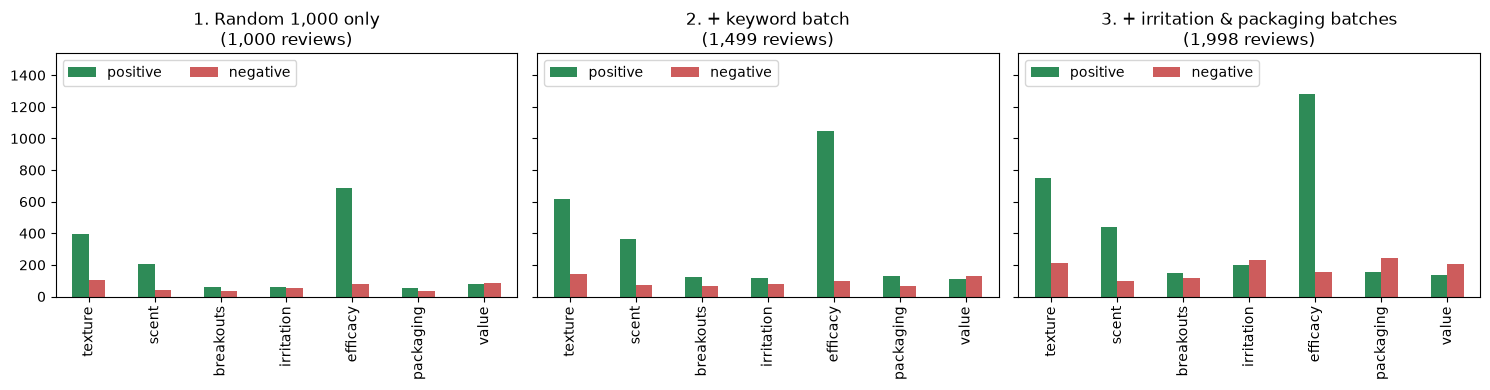

In [16]:
import matplotlib.pyplot as plt

def count_labels(data):
    """Number of positive and negative labels for each aspect."""
    return pd.DataFrame({
        "positive": [(data[a] == "positive").sum() for a in ASPECTS],
        "negative": [(data[a] == "negative").sum() for a in ASPECTS],
    }, index=ASPECTS)

stages = {
    "1. Random 1,000 only": load_labeled("llm_labels_sample1000.csv", df),
    "2. + keyword batch": pd.read_csv("skincare_reviews_llm_final.csv"),
    "3. + irritation & packaging batches": pd.read_csv("skincare_reviews_llm_final_v3.csv"),
}

# Table with the numbers
display(pd.concat({name: count_labels(data) for name, data in stages.items()}, axis=1))

# Three charts side by side (same y-axis, with some headroom for the legend)
y_max = max(count_labels(data).values.max() for data in stages.values())
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, data) in zip(axes, stages.items()):
    count_labels(data).plot(kind="bar", ax=ax, color=["seagreen", "indianred"])
    ax.set_title(f"{name}\n({len(data):,} reviews)")
    ax.set_xlabel("")
    ax.set_ylim(0, y_max * 1.2)
    ax.legend(loc="upper left", ncol=2)
plt.tight_layout()
plt.show()


### Step 12: Create and evaluate a manually reviewed gold set

Select 200 reviews that are not included in the labeled training dataset, manually annotate their aspect sentiments, and compare those annotations with the extracted labels. This provides an estimate of label agreement on a held-out sample.

In [ ]:

# Draw 200 random reviews that are NOT in the training data 

if os.path.exists("gold_to_label.xlsx"):
    raise SystemExit("gold_to_label.xlsx already exists - not overwriting your labels.")

train = pd.read_csv("skincare_reviews_llm_final_v3.csv")
pool = df[~df["review_text"].isin(train["review_text"])].drop_duplicates("review_text")
assert len(pool) >= 200, (f"Only {len(pool)} candidate reviews left: 'train' must be the labeled training file "
                           "(skincare_reviews_llm_final_v3.csv), not the full dataset.")
gold = pool.sample(200, random_state=2026)
gold[["review_text", "review_text_for_llm"]].to_csv("gold_sample.csv", index_label="review_index")

sheet = gold[["review_text"]].reset_index(names="review_index")
sheet[ASPECTS + ["done"]] = None                     # empty columns for you to fill
with pd.ExcelWriter("gold_to_label.xlsx", engine="openpyxl") as xw:
    sheet.to_excel(xw, index=False)
    ws = xw.sheets["Sheet1"]
    ws.column_dimensions["B"].width = 100
    ws.freeze_panes = "C2"
    for cell in ws["B"]:
        cell.alignment = Alignment(wrap_text=True, vertical="top")

print("Saved gold_to_label.xlsx.")

# Labeling: 
# - per aspect type p (positive) or n (negative); left EMPTY if the reviewer had no clear opinion.
# - x in 'done' when a row is finished


In [ ]:
# Check: gold-set reviews must not be in the training data
gold_check = pd.read_csv("gold_sample.csv")
train_texts = set(pd.read_csv("skincare_reviews_llm_final_v3.csv")["review_text"])
print("Gold reviews that also appear in the training data:", gold_check["review_text"].isin(train_texts).sum())


Gold reviews that also appear in the training data: 0


### Step 13: Create LLM labels for the same reviews 

In [ ]:
# Create LLM labels for the same reviews
gold = pd.read_csv("gold_sample.csv", index_col="review_index")
results_gold = run_batch_extraction(gold, text_col="review_text_for_llm", checkpoint_path="llm_labels_v3_gold.csv")
print("errors:", results_gold[ASPECTS].isin(["ERROR", "PARSE_ERROR"]).sum().sum())


200 reviews left to process.


100%|██████████| 200/200 [38:17<00:00, 11.49s/it]

errors: 0


### Step 14: Compare the LLM labels to the gold set labels

In [17]:
# Compare the LLM labels to the gold labels (from gold_to_label.xlsx). The LLM labels are in llm_labels_v3_gold.csv.

# Map the gold labels to a consistent format: "p" and "positive" become "positive", "n" and "negative" become "negative", and empty strings become "none".
#  This ensures that the comparison between gold and LLM labels is accurate and standardized.
MAP = {"": "none", "p": "positive", "positive": "positive", "n": "negative", "negative": "negative"}

# Function to tidy up a column of labels by converting them to lowercase, stripping whitespace, and mapping them to a standardized format. 
# It also checks for any unknown labels and raises an assertion error if any are found.

def tidy(col):
    out = col.astype("string").fillna("").str.strip().str.lower().map(MAP)
    bad = col[out.isna()]
    assert bad.empty, (f"Unknown label(s) in '{col.name}': {bad.unique().tolist()} "
                       f"(review_index {bad.index.tolist()[:10]}). Use p, n, or leave empty.")
    return out

# Load the gold labels from the Excel file and filter to only include rows marked as done. 
# Then, load the LLM labels from the CSV file and merge them with the gold labels on the "review_index" column. 
# An assertion checks that there are matching rows for comparison.
hand = pd.read_excel("gold_to_label.xlsx")
hand = hand[hand["done"].notna()]                                  # only rows marked as done
llm = pd.read_csv("llm_labels_v3_gold.csv")
m = hand.merge(llm, on="review_index", suffixes=("_gold", "_llm"))
assert len(m) > 0, "No rows marked done (or no matching LLM labels - run cell 2)."
print(len(m), "rows compared")

rows = []
for a in ASPECTS:
    g, p = tidy(m[a + "_gold"]), tidy(m[a + "_llm"])
    m[a + "_gold"], m[a + "_llm"] = g, p
    pr, rc, f1, n = precision_recall_fscore_support(g, p, labels=["positive", "negative"], zero_division=0)
    rows.append({
        "aspect": a, "n_pos": n[0], "n_neg": n[1],
        "P_pos": pr[0], "R_pos": rc[0], "F1_pos": f1[0],
        "P_neg": pr[1], "R_neg": rc[1], "F1_neg": f1[1],
        "over": ((g == "none") & (p != "none")).sum(),                 # LLM labeled, human did not
        "missed": ((g != "none") & (p == "none")).sum(),               # human labeled, LLM did not
        "flipped": ((g != "none") & (p != "none") & (g != p)).sum(),   # opposite polarity
    })
print(pd.DataFrame(rows).set_index("aspect").round(2).to_string())

# Create a new Excel file that contains the review index, review text, and the gold and LLM labels for each aspect.
cols = ["review_index", "review_text"] + [a + s for a in ASPECTS for s in ("_gold", "_llm")]
m[cols].to_excel("gold_vs_llm.xlsx", index=False)

196 rows compared
            n_pos  n_neg  P_pos  R_pos  F1_pos  P_neg  R_neg  F1_neg  over  missed  flipped
aspect                                                                                     
texture        72     14   0.80   0.99    0.88   1.00   0.93    0.96    18       2        0
scent          41     12   0.98   0.98    0.98   1.00   1.00    1.00     1       1        0
breakouts      16      9   0.92   0.69    0.79   0.89   0.89    0.89     1       5        1
irritation     27      9   1.00   0.74    0.85   0.80   0.89    0.84     2       8        0
efficacy      145     17   0.98   0.88    0.93   0.94   0.88    0.91     2      17        2
packaging      16      7   1.00   1.00    1.00   1.00   0.86    0.92     0       1        0
value          18     10   1.00   0.83    0.91   0.62   1.00    0.77     3       0        3


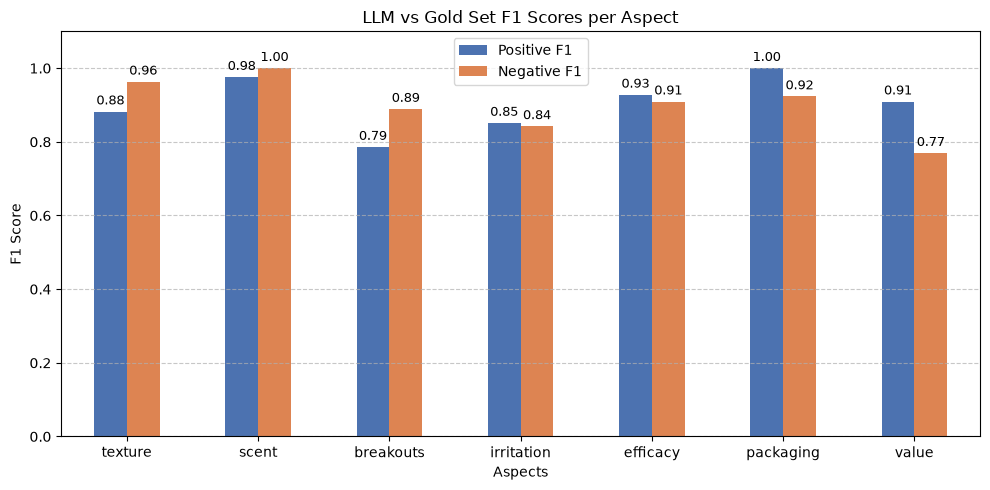

In [21]:

import matplotlib.pyplot as plt
# Visual results: bar chart of F1 scores per aspect (positive vs negative)
f1_df = pd.DataFrame({
    "Positive F1": [r["F1_pos"] for r in rows],
    "Negative F1": [r["F1_neg"] for r in rows]
}, index=ASPECTS)

ax = f1_df.plot(kind="bar", figsize=(10, 5), color=["#4c72b0", "#dd8452"], ylim=(0, 1.1))
plt.title("LLM vs Gold Set F1 Scores per Aspect")
plt.ylabel("F1 Score")
plt.xlabel("Aspects")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Add values on top of bars for readability
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, size=9)

plt.tight_layout()
plt.show()

### Gold-set validation summary
The 200 manually completed reviews provide an initial check of agreement between the extracted labels and manual annotations. Results vary by aspect and sentiment class. Scent and efficacy show strong agreement in this sample (positive-class F1: 0.98 and 0.93; negative-class F1: 1.00 and 0.91). Texture positive-class F1 is 0.88 and negative-class F1 is 0.96. Results are less consistent for breakouts, irritation, and value, where some precision or recall scores are lower. Packaging scores look strong, but the gold set contains only 16 positive and 7 negative examples, so those estimates are particularly uncertain.
Overall, these results provide an encouraging initial check of the labels used for training, but they do not establish that every label is correct or that performance will generalize to all skincare reviews. The gold set is small and class counts are uneven; metrics for aspects with few examples can change substantially with a small number of different annotations.
Known limitations
- Small manually labeled holdout set: Only 200 reviews have completed manual annotations. This is useful for an initial check, but it is not large enough to provide highly precise estimates for every aspect and sentiment class.
- Uneven class coverage: Some aspect/class combinations have few examples, especially packaging. Their precision, recall, and F1 scores should be interpreted cautiously.
- Automatically extracted training labels: The training labels were generated through an extraction pipeline and were not all independently verified by a human. Errors or inconsistencies in these labels may be learned by the downstream model.
- Targeted sampling affects distributions: Supplementary batches were selected using aspect-related keywords to enrich underrepresented cases. Their class frequencies therefore do not represent the prevalence of sentiments in the full review population.
- Keyword-based candidate selection can miss cases: Reviews that express an aspect indirectly or use different wording may not be selected for targeted labeling.
- Limited evaluation scope: The holdout results describe agreement on this sample of Sephora skincare reviews. They do not, by themselves, demonstrate performance on other datasets, product categories, or review populations.
These limitations suggest treating the current results as a baseline. A larger, more balanced manually annotated evaluation set and additional human review of uncertain or underrepresented cases would strengthen future validation.